# MILAgeScore ablation analysis: binned stratified K-fold (cv1)
Layout read: `ablation/<study>/<config>/seed<S>/fold<F>/` (`metrics.json`, `.done`, `logs/`).
Primary metric: `val/mae` (rank-space; ranks are aligned across lines because bins are pooled). Lower is better.
Every config sees the same folds, so configs are compared **paired by fold**.

In [17]:
import re, json, warnings, itertools
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import spearmanr
warnings.filterwarnings("ignore")
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 60)

STUDY_DIR     = Path("ablation/cv1")
N_BINS        = 10
USE_WANDB     = True            # only used for learning curves / gap / best epoch
WANDB_ENTITY  = None
WANDB_PROJECT = "MILAgeScore_Ablation_v3"
PRIMARY       = "val_mae"
TOPK          = 15
OUT = STUDY_DIR / "analysis"; OUT.mkdir(parents=True, exist_ok=True)
FACT = [("bag_size", "Bag size"), ("bpg", "Bags per group"), ("batch", "Batch size")]
TL, VL, VM, VMS, VR, EP = "train/loss_corn", "val/loss", "val/mae", "val/mae_s", "val/spearman_rho", "epoch"

def savefig(fig, name):
    fig.savefig(OUT / name, dpi=200, bbox_inches="tight"); plt.show()

In [18]:
# ── Discover runs ──────────────────────────────────────────────────────────────
pat = re.compile(r"bs(\d+)_bpg(\d+)_batch(\d+)")
rows = []
for d in sorted(STUDY_DIR.glob("bs*_bpg*_batch*/seed*/fold*")):
    m = pat.fullmatch(d.parent.parent.name)
    if not m:
        continue
    rec = dict(config=d.parent.parent.name, bag_size=int(m[1]), bpg=int(m[2]), batch=int(m[3]),
               seed=int(d.parent.name[4:]), fold=int(d.name[4:]), dir=d, done=(d / ".done").exists())
    rec["run"] = f"{rec['config']}_s{rec['seed']}_f{rec['fold']}"
    mp = d / "metrics.json"
    if mp.exists():
        rec.update({k.replace("/", "_"): v for k, v in json.load(open(mp)).items()})
    rows.append(rec)
runs = pd.DataFrame(rows)
usable = runs[runs.done & runs[PRIMARY].notna()].copy()
metrics = [c for c in usable.columns if c.startswith(("val_", "loco_"))
           and pd.api.types.is_numeric_dtype(usable[c])]

exp = usable.groupby("config").size()
print(f"{len(runs)} run dirs, {len(usable)} usable | seeds={sorted(usable.seed.unique())} folds={sorted(usable.fold.unique())}")
print("configs:", usable.config.nunique(), "| metrics:", metrics)
short = exp[exp < exp.max()]
if len(short): print("INCOMPLETE configs (excluded from paired stats if any fold missing):\n", short)

120 run dirs, 120 usable | seeds=[np.int64(0)] folds=[np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
configs: 24 | metrics: ['val_loss', 'val_mae', 'val_mzoe', 'val_rmse', 'val_spearman_rho', 'val_spearman_p', 'val_mae_s']


In [19]:
# ── Config-level summary: mean, SD across folds, SD across seeds, paired rank ──
keys = ["config", "bag_size", "bpg", "batch"]
summ = usable.groupby(keys)[metrics].mean().add_suffix("_mean").reset_index().set_index("config")
sd_f = usable.groupby(["config", "fold"])[metrics].mean().groupby("config").std().add_suffix("_sd_folds")
sd_s = usable.groupby(["config", "seed"])[metrics].mean().groupby("config").std().add_suffix("_sd_seeds")
summ = summ.join(sd_f).join(sd_s)

usable["rank_in_fold"] = usable.groupby(["seed", "fold"])[PRIMARY].rank()
summ["mean_rank"]  = usable.groupby("config")["rank_in_fold"].mean()
summ["top1_frac"]  = usable.assign(t=usable.rank_in_fold == 1).groupby("config")["t"].mean()
summ["top3_frac"]  = usable.assign(t=usable.rank_in_fold <= 3).groupby("config")["t"].mean()
summ = summ.sort_values(f"{PRIMARY}_mean")
summ.to_csv(OUT / "config_summary_cv.csv"); usable.drop(columns="dir").to_csv(OUT / "run_summary_cv.csv", index=False)

show = ["bag_size", "bpg", "batch", f"{PRIMARY}_mean", f"{PRIMARY}_sd_folds", f"{PRIMARY}_sd_seeds",
        "val_spearman_rho_mean", "val_mae_s_mean", "mean_rank", "top1_frac"]
show = [c for c in show if c in summ.columns]
print("Top by mean val MAE:"); print(summ[show].head(10).round(3).to_string())
print("\nWorst 3:"); print(summ[show].tail(3).round(3).to_string())

Top by mean val MAE:
                        bag_size  bpg  batch  val_mae_mean  val_mae_sd_folds  val_mae_sd_seeds  val_spearman_rho_mean  val_mae_s_mean  mean_rank  top1_frac
config                                                                                                                                                     
bs100_bpg0400_batch032       100  400     32         0.054             0.041               NaN                  0.992           0.014        1.5        0.6
bs100_bpg0050_batch064       100   50     64         0.069             0.048               NaN                  0.990           0.032        5.7        0.2
bs100_bpg0200_batch064       100  200     64         0.073             0.047               NaN                  0.990           0.024        7.8        0.0
bs100_bpg0050_batch032       100   50     32         0.075             0.028               NaN                  0.990           0.028        8.6        0.2
bs100_bpg0100_batch064       100  100     6

In [20]:
# ── Paired comparison against the best config (same folds => differences are paired) ──
piv  = usable.pivot_table(index=["seed", "fold"], columns="config", values=PRIMARY)
best = summ.index[0]
diff = piv.sub(piv[best], axis=0)                 # > 0 means worse than best
paired = pd.DataFrame({"mean_diff": diff.mean(), "sd_diff": diff.std(),
                       "worse_in_frac": (diff > 0).mean(), "n": diff.count()}).drop(best)
paired["t_like"] = paired.mean_diff / (paired.sd_diff / np.sqrt(paired.n))
paired = paired.sort_values("mean_diff")
print(f"Best config: {best}  (differences are config - best, per seed/fold)")
print(paired.head(12).round(3).to_string())
n_fold = piv.shape[0]
print(f"\nNote: with {n_fold} paired (seed,fold) units, a config within ~1 SD of the paired difference "
      f"is not separable from the best; treat those as a tied group.")
tied = paired[paired.mean_diff < 2 * paired.sd_diff / np.sqrt(paired.n)].index.tolist()
print("Configs not clearly worse than best (mean_diff < 2 SE):", [best] + tied)

Best config: bs100_bpg0400_batch032  (differences are config - best, per seed/fold)
                        mean_diff  sd_diff  worse_in_frac  n  t_like
config                                                              
bs100_bpg0050_batch064      0.015    0.013            0.8  5   2.548
bs100_bpg0200_batch064      0.019    0.020            1.0  5   2.123
bs100_bpg0050_batch032      0.021    0.023            0.8  5   1.967
bs100_bpg0100_batch064      0.021    0.016            1.0  5   2.997
bs100_bpg0100_batch128      0.022    0.016            0.8  5   3.057
bs100_bpg0200_batch032      0.025    0.014            1.0  5   4.037
bs100_bpg0050_batch128      0.025    0.018            1.0  5   3.057
bs100_bpg0400_batch064      0.025    0.015            1.0  5   3.772
bs100_bpg0100_batch032      0.027    0.015            1.0  5   4.104
bs100_bpg0400_batch128      0.027    0.017            1.0  5   3.653
bs100_bpg0200_batch128      0.034    0.016            1.0  5   4.787
bs050_bpg0400_batch

In [21]:
# ── Marginals (mean over other factors; SD over fold means) + standardised linear effects ──
for f, lab in FACT:
    t = usable.groupby([f, "fold"])[metrics].mean().groupby(f).agg(["mean", "std"])
    out = pd.DataFrame({m: t[(m, "mean")].round(3).astype(str) + " ± " + t[(m, "std")].round(3).astype(str)
                        for m in [PRIMARY, "val_spearman_rho", "val_loss"] if m in metrics})
    print(f"--- {lab} ---"); print(out.to_string())
    usable.groupby(f)[metrics].mean().to_csv(OUT / f"marginal_{f}.csv")

X = np.log2(usable[[f for f, _ in FACT]].astype(float)); X = (X - X.mean()) / X.std()
A = np.c_[np.ones(len(X)), X.values]
for tg in [m for m in [PRIMARY, "val_spearman_rho", "val_loss"] if m in metrics]:
    y = usable[tg].values; c, *_ = np.linalg.lstsq(A, (y - y.mean()) / y.std(), rcond=None)
    print(f"{tg:18s} std. coef", dict(zip([f for f, _ in FACT], c[1:].round(3))))
print("(linear in log2 factors; a guide only - interactions exist)")

--- Bag size ---
                val_mae val_spearman_rho       val_loss
bag_size                                               
50        0.109 ± 0.048    0.987 ± 0.003  0.064 ± 0.017
100       0.076 ± 0.044    0.989 ± 0.002  0.061 ± 0.017
--- Bags per group ---
           val_mae val_spearman_rho       val_loss
bpg                                               
50   0.099 ± 0.044    0.988 ± 0.002  0.074 ± 0.018
100  0.094 ± 0.048    0.988 ± 0.003  0.066 ± 0.015
200  0.091 ± 0.042    0.989 ± 0.002  0.059 ± 0.015
400   0.086 ± 0.05    0.989 ± 0.003   0.051 ± 0.02
--- Batch size ---
             val_mae val_spearman_rho       val_loss
batch                                               
32      0.09 ± 0.041    0.989 ± 0.002  0.053 ± 0.019
64     0.089 ± 0.048    0.989 ± 0.003  0.059 ± 0.018
128     0.099 ± 0.05    0.987 ± 0.003  0.075 ± 0.017
val_mae            std. coef {'bag_size': np.float64(-0.345), 'bpg': np.float64(-0.093), 'batch': np.float64(0.075)}
val_spearman_rho   std. coef 

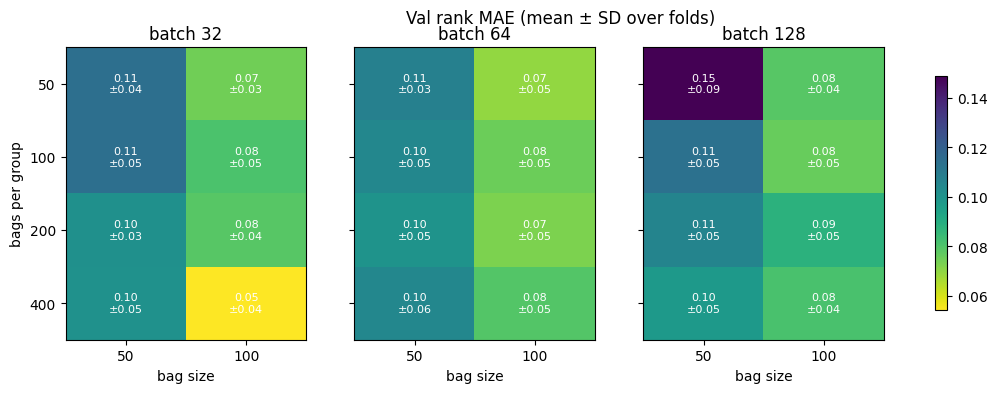

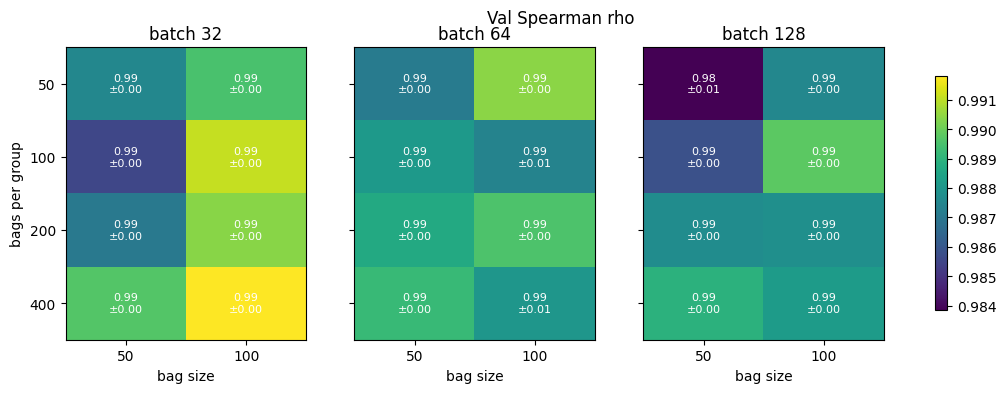

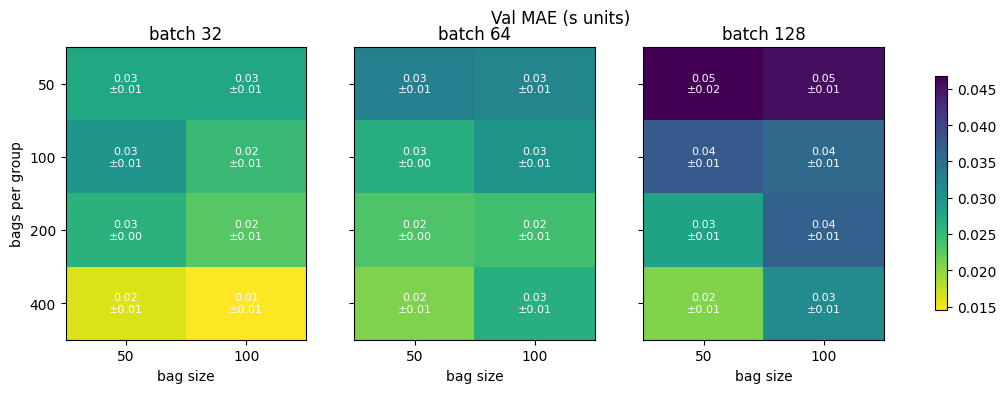

In [22]:
# ── Heatmaps: bags-per-group x bag size, one panel per batch size (mean ± SD over folds) ──
def heat(metric, title, cmap="viridis_r"):
    bs = sorted(summ.batch.unique())
    fig, axes = plt.subplots(1, len(bs), figsize=(4.4 * len(bs), 3.8), sharey=True)
    axes = np.atleast_1d(axes)
    lo, hi = summ[f"{metric}_mean"].min(), summ[f"{metric}_mean"].max()
    for ax, b in zip(axes, bs):
        s = summ[summ.batch == b]
        mu = s.pivot(index="bpg", columns="bag_size", values=f"{metric}_mean").sort_index()
        sd = s.pivot(index="bpg", columns="bag_size", values=f"{metric}_sd_folds").reindex_like(mu)
        im = ax.imshow(mu.values, cmap=cmap, vmin=lo, vmax=hi, aspect="auto")
        ax.set_xticks(range(mu.shape[1])); ax.set_xticklabels(mu.columns)
        ax.set_yticks(range(mu.shape[0])); ax.set_yticklabels(mu.index)
        for i, j in itertools.product(range(mu.shape[0]), range(mu.shape[1])):
            ax.text(j, i, f"{mu.values[i, j]:.2f}\n±{sd.values[i, j]:.2f}", ha="center", va="center", color="w", fontsize=8)
        ax.set_title(f"batch {b}"); ax.set_xlabel("bag size")
    axes[0].set_ylabel("bags per group"); fig.suptitle(title); fig.colorbar(im, ax=list(axes), shrink=.8)
    savefig(fig, f"heatmap_{metric}.png")
for m, t, c in [(PRIMARY, "Val rank MAE (mean ± SD over folds)", "viridis_r"),
                ("val_spearman_rho", "Val Spearman rho", "viridis"), ("val_mae_s", "Val MAE (s units)", "viridis_r")]:
    if f"{m}_mean" in summ.columns: heat(m, t, c)

Config-ranking Spearman between folds: mean 0.491, min 0.224
Best config per fold:
fold
0    bs100_bpg0400_batch032
1    bs100_bpg0400_batch032
2    bs100_bpg0050_batch064
3    bs100_bpg0400_batch032
4    bs100_bpg0050_batch032


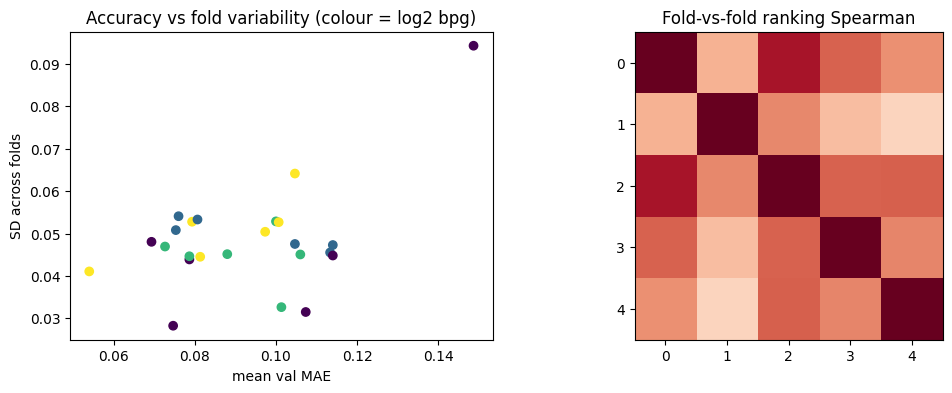

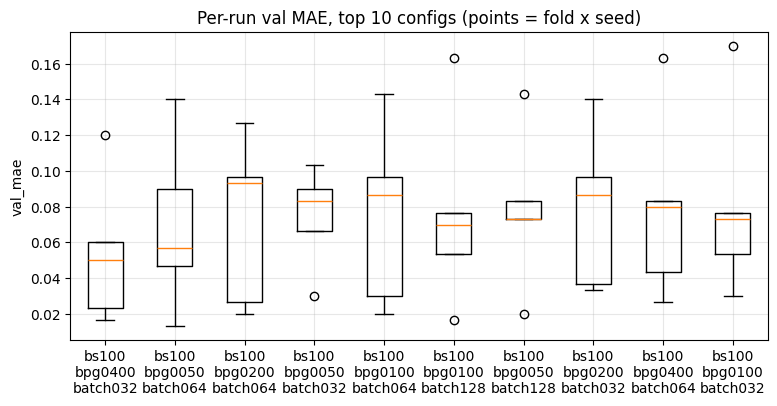

In [23]:
# ── Fold-to-fold agreement: does the config ranking replicate across folds? ──
pf = usable.groupby(["fold", "config"])[PRIMARY].mean().unstack()          # folds x configs
sp = pf.T.corr(method="spearman"); iu = np.triu_indices(len(sp), 1)
print(f"Config-ranking Spearman between folds: mean {sp.values[iu].mean():.3f}, min {sp.values[iu].min():.3f}")
print("Best config per fold:"); print(pf.idxmin(axis=1).to_string())

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].scatter(summ[f"{PRIMARY}_mean"], summ[f"{PRIMARY}_sd_folds"], c=np.log2(summ.bpg), cmap="viridis")
ax[0].set_xlabel("mean val MAE"); ax[0].set_ylabel("SD across folds"); ax[0].set_title("Accuracy vs fold variability (colour = log2 bpg)")
ax[1].imshow(sp.values, vmin=-1, vmax=1, cmap="RdBu_r"); ax[1].set_title("Fold-vs-fold ranking Spearman")
ax[1].set_xticks(range(len(sp))); ax[1].set_yticks(range(len(sp)))
savefig(fig, "fold_agreement.png")

fig, ax = plt.subplots(figsize=(9, 4))
top = summ.index[:10]
ax.boxplot([usable[usable.config == c][PRIMARY] for c in top], labels=[c.replace("_", "\n") for c in top])
ax.set_ylabel(PRIMARY); ax.set_title("Per-run val MAE, top 10 configs (points = fold x seed)"); ax.grid(alpha=.3)
savefig(fig, "top_configs_box.png")

matched 120/120 W&B runs
                        best_epoch  n_epochs   gap  steps_to_best
config                                                           
bs100_bpg0400_batch032        14.4      29.4  0.02         1800.0
bs100_bpg0050_batch064        35.4      50.4  0.03          247.8
bs100_bpg0200_batch064        15.4      30.4  0.03          477.4
bs100_bpg0050_batch032        21.8      36.8  0.03          327.0
bs100_bpg0100_batch064        16.8      31.8  0.03          252.0
bs100_bpg0100_batch128        30.4      45.4  0.02          212.8
bs100_bpg0050_batch128        48.4      63.4  0.03          145.2
bs100_bpg0200_batch032        11.4      26.4  0.02          706.8
bs100_bpg0400_batch064        13.4      28.4  0.03          830.8
bs100_bpg0100_batch032        13.6      28.6  0.03          421.6
(train loss has dropout ON, val OFF: gap is a relative indicator, not a clean overfitting measure)


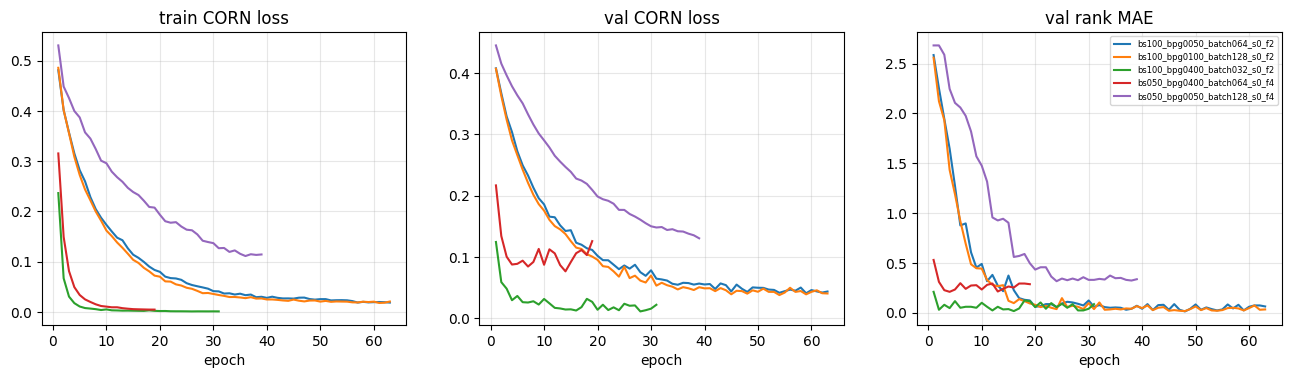

In [24]:
# ── Optional: W&B histories -> best epoch, train/val loss, gap, steps (needs wandb login) ──
extras = None
if USE_WANDB:
    try:
        import wandb
        api = wandb.Api(); ent = WANDB_ENTITY or api.default_entity
        names = set(usable.run); hist = {}
        for r in api.runs(f"{ent}/{WANDB_PROJECT}"):
            if r.name in names and r.name not in hist:
                hist[r.name] = r.history(samples=100000, pandas=True)
        print(f"matched {len(hist)}/{len(names)} W&B runs")
        recs = []
        for n, h in hist.items():
            e = h.groupby(EP)[[TL, VL, VM]].first().dropna(subset=[VM])
            b = e[VM].idxmin()
            recs.append(dict(run=n, n_epochs=len(e), best_epoch=b, train_loss=e.loc[b, TL], val_loss=e.loc[b, VL]))
        extras = pd.DataFrame(recs).merge(usable[["run", "config", "bpg", "batch", "bag_size", "fold", "seed"]], on="run")
        extras["gap"] = extras.val_loss - extras.train_loss
        extras["steps_per_epoch"] = (N_BINS * extras.bpg) // extras.batch
        extras["steps_to_best"] = extras.steps_per_epoch * extras.best_epoch
        extras.to_csv(OUT / "wandb_extras.csv", index=False)
        print(extras.groupby("config")[["best_epoch", "n_epochs", "gap", "steps_to_best"]].mean().round(2).loc[summ.index[:10]])
        print("(train loss has dropout ON, val OFF: gap is a relative indicator, not a clean overfitting measure)")
        fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
        for n in [r for r in usable.sort_values(PRIMARY).run.head(3)] + [r for r in usable.sort_values(PRIMARY).run.tail(2)]:
            if n in hist:
                e = hist[n].groupby(EP)[[TL, VL, VM]].first()
                for a, c in zip(ax, [TL, VL, VM]): a.plot(e.index, e[c], label=n)
        for a, t in zip(ax, ["train CORN loss", "val CORN loss", "val rank MAE"]): a.set_title(t); a.set_xlabel("epoch"); a.grid(alpha=.3)
        ax[2].legend(fontsize=6); savefig(fig, "learning_curves.png")
    except Exception as ex:
        print("W&B step skipped:", repr(ex))

In [25]:
# ── Attention concentration (needs --mode all) ──
def load_first(r, pattern):
    fs = sorted((r.dir / "logs").glob(pattern)); return pd.read_csv(fs[0]) if fs else None
def bag_stats(w):
    w = np.asarray(w, float); w = w / w.sum(); n = len(w)
    h = -(w * np.log(w + 1e-12)).sum(); k = max(1, int(np.ceil(.1 * n)))
    return h / np.log(n), w.max() * n, np.sort(w)[-k:].sum(), np.exp(h) / n
ATTW = None; att_rows = []
for r in usable.itertuples():
    a = load_first(r, "*attention*.csv")
    if a is None: continue
    if ATTW is None:
        num = a.select_dtypes("number").columns.tolist()
        ATTW = next((c for c in num if re.search(r"attn|attention|weight|alpha", c, re.I)), None)
    if ATTW:
        s = bag_stats(a[ATTW].values)
        att_rows.append(dict(run=r.run, norm_entropy=s[0], maxw_x_uniform=s[1], top10pct_mass=s[2], eff_cell_fraction=s[3]))
if att_rows:
    att = pd.DataFrame(att_rows).merge(usable[["run", "config", "bag_size", "bpg", "batch", PRIMARY]], on="run")
    att.to_csv(OUT / "attention_metrics.csv", index=False)
    print("weight col:", ATTW, "| runs:", len(att))
    print(att[["norm_entropy", "maxw_x_uniform", "top10pct_mass", "eff_cell_fraction", PRIMARY]].corr(method="spearman")[PRIMARY].round(2))
    print(att.groupby("bag_size")[["norm_entropy", "maxw_x_uniform", "top10pct_mass"]].mean().round(3))
else:
    print("No attention CSVs found (run with --mode all to produce them).")

weight col: mean_attention | runs: 116
norm_entropy         0.65
maxw_x_uniform      -0.71
top10pct_mass       -0.64
eff_cell_fraction    0.65
val_mae              1.00
Name: val_mae, dtype: float64
          norm_entropy  maxw_x_uniform  top10pct_mass
bag_size                                             
50               0.997           2.491          0.151
100              0.996           2.644          0.155


In [26]:
# ── Feature-importance consensus + what drives disagreement (hyperparameters vs data folds) ──
def load_imp(r):
    t = load_first(r, "*importance_normalised*.csv")
    if t is None: return None
    f = t.columns[0] if t.iloc[:, 0].dtype == object else next(c for c in t.columns if t[c].dtype == object)
    v = next((c for c in t.select_dtypes("number").columns if re.search(r"imp|attr|ig|norm", c, re.I)), t.select_dtypes("number").columns[0])
    s = t.set_index(f)[v].abs(); return s / s.sum()
cols = {r.run: load_imp(r) for r in usable.itertuples()}
cols = {k: v for k, v in cols.items() if v is not None}
if cols:
    M = pd.DataFrame(cols).fillna(0); rank = M.rank(ascending=False)
    cons = pd.DataFrame({"mean_share": M.mean(1), "sd_share": M.std(1), "mean_rank": rank.mean(1),
                         "rank_sd": rank.std(1), f"in_top{TOPK}_frac": (rank <= TOPK).mean(1)}).sort_values("mean_rank")
    cons.to_csv(OUT / "feature_consensus.csv"); print(M.shape); print(cons.head(20).round(4))
    sp = M.corr(method="spearman"); meta = usable.set_index("run").loc[M.columns]
    same_cfg  = (meta.config.values[:, None] == meta.config.values[None, :])
    same_fold = (meta.fold.values[:, None] == meta.fold.values[None, :])
    iu = np.triu_indices(len(sp), 1); v = sp.values[iu]
    for lab, mask in [("same config, different fold/seed", same_cfg & ~same_fold),
                      ("same fold, different config", same_fold & ~same_cfg),
                      ("different config and fold", ~same_cfg & ~same_fold)]:
        mm = mask[iu]
        if mm.any(): print(f"{lab:36s} mean Spearman {v[mm].mean():.3f}  (n={mm.sum()})")
else:
    print("No importance CSVs found (run with --mode all to produce them).")

StopIteration: 

Testing prediction for run: C:\Users\goofy\PycharmProjects\MILAgeScore\ablation\cv1\bs100_bpg0200_batch064\seed0\fold0
Device: NVIDIA GeForce RTX 5070 Ti  |  Compute capability: sm_120
Model input dimensions resolved:
  feature_set : both
  n_manual    : 42  (of 42)
  n_latent    : 16  (of 16)
  in_features : 58

Block weights:
  n_manual=42  n_latent=16  ratio=0.38x
  w_manual=0.6172  w_latent=1.0000  (default sqrt(ratio))

MILAgeScoreModel built:
  in_features   : 58
  num_classes   : 10
  Parameters    : 37,897
  Architecture  :
    InstanceEncoder   : 58 → 64 → 128
    AttentionAggregator: 128 → attention_dim=64 → 128
    CORNHead          : 128 → 64 → 9
Loaded processed data:
  features_manual : (16505, 42)
  features_latent : (16505, 16)
  labels          : (16505, 9)
  manual_cols     : 42
  latent_cols     : 16


Evaluating passage trajectory: 100%|██████████| 27/27 [00:00<00:00, 29.00it/s]



Passage Trajectory Evaluation:
  Spearman ρ : 0.9907  (p=0.0000)
  MAE (s)    : 0.0211

cell_line  passage  s_true  s_hat_mean  s_hat_std  rank_mean  n_cells
        1        4  0.0000      0.0001     0.0000       0.00      437
        1        5  0.0000      0.1803     0.0630       1.24      566
        1        6  0.1111      0.1118     0.0014       1.00     1051
        1        7  0.2222      0.2238     0.0014       2.00      441
        1        8  0.3333      0.3388     0.0163       3.00     1628
        1        9  0.4444      0.4472     0.0047       4.00      578
        1       10  0.5556      0.5450     0.0048       5.00      757
        1       11  0.6667      0.6616     0.0023       6.00      509
        1       12  0.7778      0.7250     0.0251       6.88      451
        1       13  0.8889      0.8721     0.0084       8.00      359
        1       14  1.0000      0.9167     0.0378       8.56      330
        1       15  1.0000      0.9883     0.0031       9.00      334
 

,cell_line,passage,bin,s_true,s_hat_mean,s_hat_std,rank_mean,err,n_cells
0,1,4,0,0.0000,0.0001,0.0000,0.00,0.0001,437
1,1,5,0,0.0000,0.1803,0.0630,1.24,0.1803,566
2,1,6,1,0.1111,0.1118,0.0014,1.00,0.0007,1051
3,1,7,2,0.2222,0.2238,0.0014,2.00,0.0016,441
4,1,8,3,0.3333,0.3388,0.0163,3.00,0.0055,1628
5,1,9,4,0.4444,0.4472,0.0047,4.00,0.0028,578
6,1,10,5,0.5556,0.5450,0.0048,5.00,-0.0106,757
7,1,11,6,0.6667,0.6616,0.0023,6.00,-0.0051,509
8,1,12,7,0.7778,0.7250,0.0251,6.88,-0.0528,451
9,1,13,8,0.8889,0.8721,0.0084,8.00,-0.0168,359



Per-line diagnostics


,MAE_s,bias_s,mean_sd,spearman,n_passages
cell_line,,,,,
1,0.0309,0.0009,0.0140,0.9930,12.0
2,0.0132,-0.0032,0.0102,0.9929,15.0


NameError: name 'save_fig' is not defined

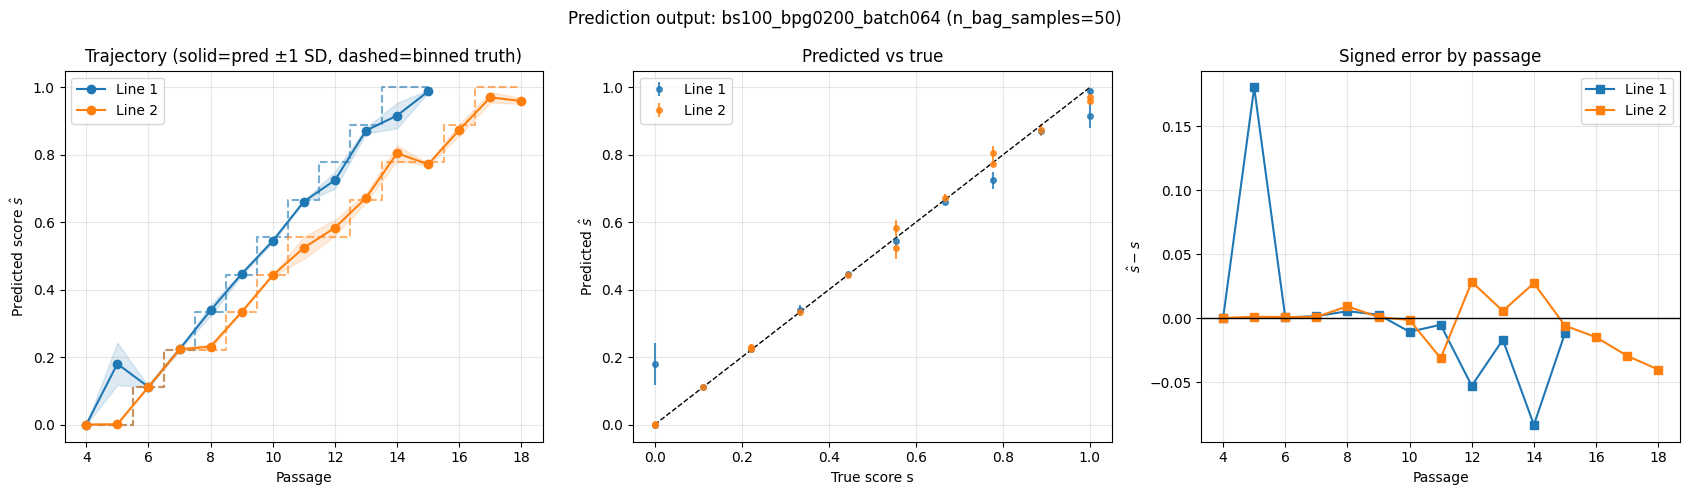

In [30]:
# ── Prediction output test for a selected run ────────────────────────────────
import torch
import sys
from src.evaluate import evaluate_passage_trajectory
from src.dataset import load_processed, apply_scalers, load_scalers
from src.model import build_model
from src.utils import get_device, resolve_model_dims, resolve_block_weights
from src.binning import prepare_binned_labels

# 1. Selection
selected_run_dir = Path(r'C:\Users\goofy\PycharmProjects\MILAgeScore\ablation\cv1\bs100_bpg0200_batch064\seed0\fold0') #usable.iloc[2]['dir'] # Use the best or first usable run
n_bags_to_test = 50 # "Take a new bag or number of bags from each passage/line combo"

print(f"Testing prediction for run: {selected_run_dir}")
ckpt_path = list((selected_run_dir / "checkpoints").glob("*_best.pt"))[0]

# 2. Load model and config
ckpt = torch.load(ckpt_path, map_location="cpu", weights_only=False)
cfg = ckpt['cfg']
device = get_device(cfg)
ckpt = torch.load(ckpt_path, map_location=device, weights_only=False)
encoder = ckpt['encoder']

in_features, n_manual, n_latent = resolve_model_dims(cfg['data']['processed_dir'], cfg['data'].get('feature_set', 'both'))
w_manual, w_latent = resolve_block_weights(n_manual, n_latent, cfg)

model = build_model(cfg, in_features, encoder.num_classes)
model.load_state_dict(ckpt['model_state'])
model.to(device); model.eval()

# 3. Load and scale data
features_manual, features_latent, labels_df, _, _ = load_processed(cfg['data']['processed_dir'])
scaler_manual, scaler_latent = load_scalers(cfg['data']['processed_dir'])
features_manual, features_latent = apply_scalers(features_manual, features_latent, scaler_manual, scaler_latent)

# 4. Prepare evaluation frame (with binning info)
labels_df_binned = prepare_binned_labels(labels_df, cfg['validation'].get('n_bins', 10))
eval_df = labels_df_binned.copy()
eval_df['cell_line'] = eval_df['cell_line_orig']
eval_df['passage'] = eval_df['passage_orig']

# 5. Run inference
cfg['evaluate'] = cfg.get('evaluate', {}); cfg['evaluate']['n_bag_samples'] = n_bags_to_test
trajectory_df = evaluate_passage_trajectory(
    model=model, features_manual=features_manual, features_latent=features_latent,
    labels_df=eval_df, encoder=encoder, device=device, cfg=cfg,
    w_manual=w_manual, w_latent=w_latent
)

# ---- 6. Report: per-passage prediction table -------------------------------
traj = trajectory_df.copy()
traj["bin"] = traj.apply(lambda x: bin_map.get((x["cell_line"], x["passage"])), axis=1)
traj["err"] = traj["s_hat_mean"] - traj["s_true"]
traj["abs_err"] = traj["err"].abs()

cols = ["cell_line", "passage", "bin", "s_true", "s_hat_mean", "s_hat_std",
        "rank_mean", "err", "n_cells"]
cols = [c for c in cols if c in traj.columns]
print("Prediction summary table")
display(traj[cols].round(4))

# ---- Per-cell-line diagnostics ---------------------------------------------
diag = (traj.groupby("cell_line")
            .apply(lambda d: pd.Series({
                "MAE_s": d["abs_err"].mean(),
                "bias_s": d["err"].mean(),
                "mean_sd": d["s_hat_std"].mean(),
                "spearman": spearmanr(d["passage"], d["s_hat_mean"])[0],
                "n_passages": len(d)}))
            .round(4))
print("\nPer-line diagnostics")
display(diag)

# ---- 7. Plots ---------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# (a) predicted trajectory vs passage, with true-score steps
ax = axes[0]
for line, d in traj.groupby("cell_line"):
    d = d.sort_values("passage")
    p = ax.plot(d["passage"], d["s_hat_mean"], marker="o", label=f"Line {line}")
    c = p[0].get_color()
    ax.fill_between(d["passage"], d["s_hat_mean"] - d["s_hat_std"],
                    d["s_hat_mean"] + d["s_hat_std"], color=c, alpha=0.15)
    ax.step(d["passage"], d["s_true"], where="mid", color=c, ls="--", alpha=0.6)
ax.set(xlabel="Passage", ylabel="Predicted score $\\hat{s}$",
       title="Trajectory (solid=pred ±1 SD, dashed=binned truth)")
ax.legend(); ax.grid(alpha=0.3)

# (b) predicted vs true score
ax = axes[1]
for line, d in traj.groupby("cell_line"):
    ax.errorbar(d["s_true"], d["s_hat_mean"], yerr=d["s_hat_std"],
                fmt="o", ms=4, alpha=0.8, label=f"Line {line}")
ax.plot([0, 1], [0, 1], "k--", lw=1)
ax.set(xlabel="True score s", ylabel="Predicted $\\hat{s}$", title="Predicted vs true")
ax.legend(); ax.grid(alpha=0.3)

# (c) residual by passage (where does the model err?)
ax = axes[2]
for line, d in traj.groupby("cell_line"):
    d = d.sort_values("passage")
    ax.plot(d["passage"], d["err"], marker="s", label=f"Line {line}")
ax.axhline(0, color="k", lw=1)
ax.set(xlabel="Passage", ylabel="$\\hat{s} - s$", title="Signed error by passage")
ax.legend(); ax.grid(alpha=0.3)

fig.suptitle(f"Prediction output: {selected_run_dir.parent.parent.name} "
             f"(n_bag_samples={n_bags_to_test})")
fig.tight_layout()
#save_fig(fig, "prediction_test_output.png")